# Regresja liniowa

### Przygotowanie środowiska programistycznego

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylab as py

#Increase plots font size
params = {'legend.fontsize': 'xx-large',
              'figure.figsize': (10, 7),
              'axes.labelsize': 'xx-large',
              'axes.titlesize':'xx-large',
              'xtick.labelsize':'xx-large',
              'ytick.labelsize':'xx-large'}
plt.rcParams.update(params)

# Zapoznanie się z regresją liniową
* W ramach tego ćwiczenia będziemy chcieli opisać zbiór danych modelem liniowym.
* Zbiór danych stworzymy sami w sposób sztuczny, ale w typowych problemach zebranie i obróbka danych stanowi znaczącą część pracy.
* Nasz liniowy model ma postać: $y = \theta_0 + \theta_1 x$
* Dane wytworzymy dla konkretnych $\theta_0$ i $\theta_1$, a następnie zaimplementujemy regresję liniową, aby znaleźć jak najlepsze oszacowanie dla tych parametrów.
* `(X,Y)` to ciąg uczący. *Co to ciąg uczący?*

## Produkcja danych

Dane wytorzymy według liniowej zależnośći

$$
{\Huge
y = \theta_0 + \theta_1 \cdot x
}
$$

Ustalamy parametry dla symulacji na $\theta_0 = 1$ i $\theta_1 = 3$. Dla wygody włóżmy oba parametry do wektora (np.array):

$$
{\Huge
\vec{\theta} = (\theta_{0}, \theta_{1})
}
$$

In [2]:
theta0 = 1
theta1 = 3
theta = np.array([theta0, theta1])

Użyjemy **nPoints** równoodległych punktów $x$ i dla nich wygenerujmy punkty wg. założonego modelu.

Dla wygody dane załadujemy do obiektu DataFrame. By to zrobić musimy zmienić wektor wierszowy na kolumnowy.

In [3]:
nPoints = 100
x = np.linspace(0, 10, nPoints)

df = pd.DataFrame(data=x.T, columns = ["x"])
df["y"] = theta[0] + df["x"]*theta[1]

**Proszę:**

* do danych "czystych" dodać kolumnę z danymi z szumem Gaussowskim: $$ y_{noise} = y + Rand(N(0,1)) $$
* Jako ciekawostka wyjaśnienie różnicy między dwoma sposobami generowania liczb losowych [tutaj](https://builtin.com/data-science/numpy-random-seed#:~:text=default_rng()%20creates%20isolated%20generators,random%20numbers%2C%20ensuring%20reproducible%20results).

In [4]:
noise = np.random.normal(0,1, nPoints)

df["y_noise"] = df["y"] + noise

print(df)

           x          y    y_noise
0    0.00000   1.000000   0.332164
1    0.10101   1.303030   0.894800
2    0.20202   1.606061   1.107457
3    0.30303   1.909091   2.760264
4    0.40404   2.212121   2.219271
..       ...        ...        ...
95   9.59596  29.787879  30.588048
96   9.69697  30.090909  30.471039
97   9.79798  30.393939  31.656565
98   9.89899  30.696970  31.390274
99  10.00000  31.000000  31.645623

[100 rows x 3 columns]


Obejrzyjmy te dane.

**Proszę narysować:**
* na jednym rysunku: `y vs x` oraz `y_noise vs x`
* na drugim rysunku: histogram `y - y_noise`   

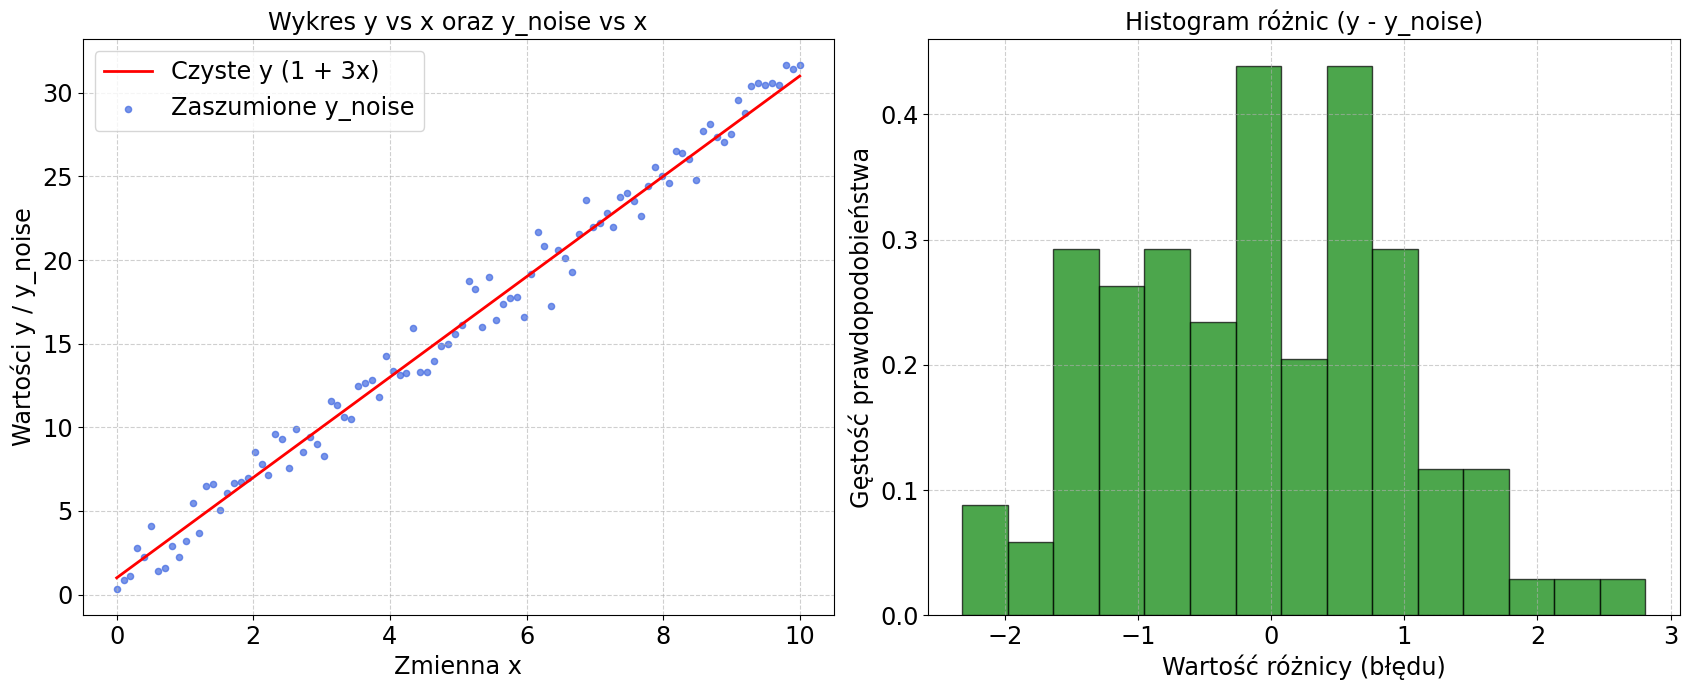

In [13]:
# --- RYSUNEK 1: Porównanie danych czystych i zaszumionych ---
plt.figure(figsize=(17, 7))

plt.subplot(1, 2, 1)  # 1 wiersz, 2 kolumny, wykres nr 1
plt.plot(df["x"], df["y"], color="red", label="Czyste y (1 + 3x)", linewidth=2)
plt.scatter(df["x"], df["y_noise"], color="royalblue", alpha=0.7, label="Zaszumione y_noise", s=20)
plt.title("Wykres y vs x oraz y_noise vs x")
plt.xlabel("Zmienna x")
plt.ylabel("Wartości y / y_noise")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# --- RYSUNEK 2: Histogram różnic (y - y_noise) ---
plt.subplot(1, 2, 2)  # 1 wiersz, 2 kolumny, wykres nr 2
# Obliczamy różnicę (czysty sygnał minus zaszumiony, czyli ujemny szum)
roznica = df["y"] - df["y_noise"]

# Rysujemy histogram (bins=15 dzieli zakres na 15 słupków)
plt.hist(roznica, bins=15, color="green", edgecolor="black", alpha=0.7, density=True)

plt.title("Histogram różnic (y - y_noise)")
plt.xlabel("Wartość różnicy (błędu)")
plt.ylabel("Gęstość prawdopodobieństwa")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()  # Automatyczne dopasowanie odstępów między wykresami

plt.show()

## Algorytm gradientowy stochastyczny

**Proszę** napisać funkcję ```iterative_stochastic_gradient(x,y, theta, alpha, nIter)``` która:
* na wejściu przyjmuje ciąg uczący w postaci wektorów x i y, wartości początkowe $(\theta_{0}, \theta_{1})$, parametr szybkości zbiegania $\alpha$ oraz liczbę iteracji `nIter`
* implementuje wzór na parametry optymalne na podstawie [algorytmu najmniejszych kwadratów](https://brain.fuw.edu.pl/edu/index.php/Uczenie_maszynowe_i_sztuczne_sieci_neuronowe/Wyk%C5%82ad_1#Algorytm_najmniejszych_kwadrat.C3.B3w).
* zwraca estymowane parametry $(\theta_{0}^{est}, \theta_{1}^{est})$ dla wszystkich iteracji, czyli tablicę o kształcie
 $(nIter+1, 2)$. Początkową wartość $(\theta_{0}^{est}, \theta_{1}^{est})$ także należy dołączyć, stąd `nIter+1` elementów
* funkcja powinna być przetestowana na czystych danych, czyli parze $(x,y)$ z poczatkową wartością $(\theta_{0}, \theta_{1})$ **równą** nominalnej
* funkcja powinna być przetestowana na czystych danych, czyli parze $(x,y)$ z poczatkową wartością $(\theta_{0}, \theta_{1})$ **różną** od nominalnej

In [23]:
%%time
def iterative_stochastic_gradient(x, y, init_theta, alpha, nIter):

    theta = np.copy(init_theta).astype(float)
    theta_est_hist = [theta]

    X_matrix = np.column_stack((np.ones(len(x)), x)) # Tworzymy macierz X o kształcie (100, 2) - pierwsza kolumna to jedynki, druga to x

    indices = np.random.randint(low=0, high=len(x)-1, size=(nIter))
    for iteration in range(nIter):
          idx = indices[iteration]

          # 2. Wyciągamy cały wiersz z macierzy X (czyli wektor [1, xi]) oraz prawdziwe yi
          xi_vector = X_matrix[idx]  # To jest wektor np. [1, 4.5]
          yi = y[idx]

          # 3. Obliczenie błędu macierzowo (iloczyn skalarny wektora xi i wektora theta)
          # np.dot(xi_vector, theta) da dokładnie: 1*theta[0] + xi*theta[1]
          error = np.dot(xi_vector, theta) - yi

          # 4. Aktualizacja całego wektora theta NARAZ jednej linii!
          theta = theta - alpha * error * xi_vector

          theta_est_hist.append(np.copy(theta))

    return np.vstack(theta_est_hist)


theta_est_hist = iterative_stochastic_gradient(df["x"], df["y"], theta, 0.01,1000)
print("Wartości estymowane z użyciem nominalnej wartości początkowej parametrów theta:",theta_est_hist[-1])

theta_est_hist = iterative_stochastic_gradient(df["x"], df["y"], theta+3, 0.01, 1000)
print("Wartości estymowane z użyciem różnej od nominalnej wartości początkowej parametrów theta:",theta_est_hist[-1])

Wartości estymowane z użyciem nominalnej wartości początkowej parametrów theta: [1. 3.]
Wartości estymowane z użyciem różnej od nominalnej wartości początkowej parametrów theta: [1.22670664 2.95978392]
CPU times: user 20.9 ms, sys: 6.98 ms, total: 27.9 ms
Wall time: 25.5 ms


**Proszę** narysować następujące rysunki:
* dane, oraz krzywe regresji dla 10 iteracji na jednym rysunku
* wartości parametrów $\theta_{0}$ i $\theta_{1}$ w funkcji numeru iteracji dla $\alpha$ = 0.1, 0.05 oraz 0.01 oraz 10 iteracji
* wartości parametrów $\theta_{0}$ i $\theta_{1}$ w funkcji numeru iteracji dla $\alpha$ = 0.01 dla 100 iteracji

W każdym przypadku jako wartości początkowe proszę przyjąć ($\theta_{0}$, $\theta_{1}$) + 1

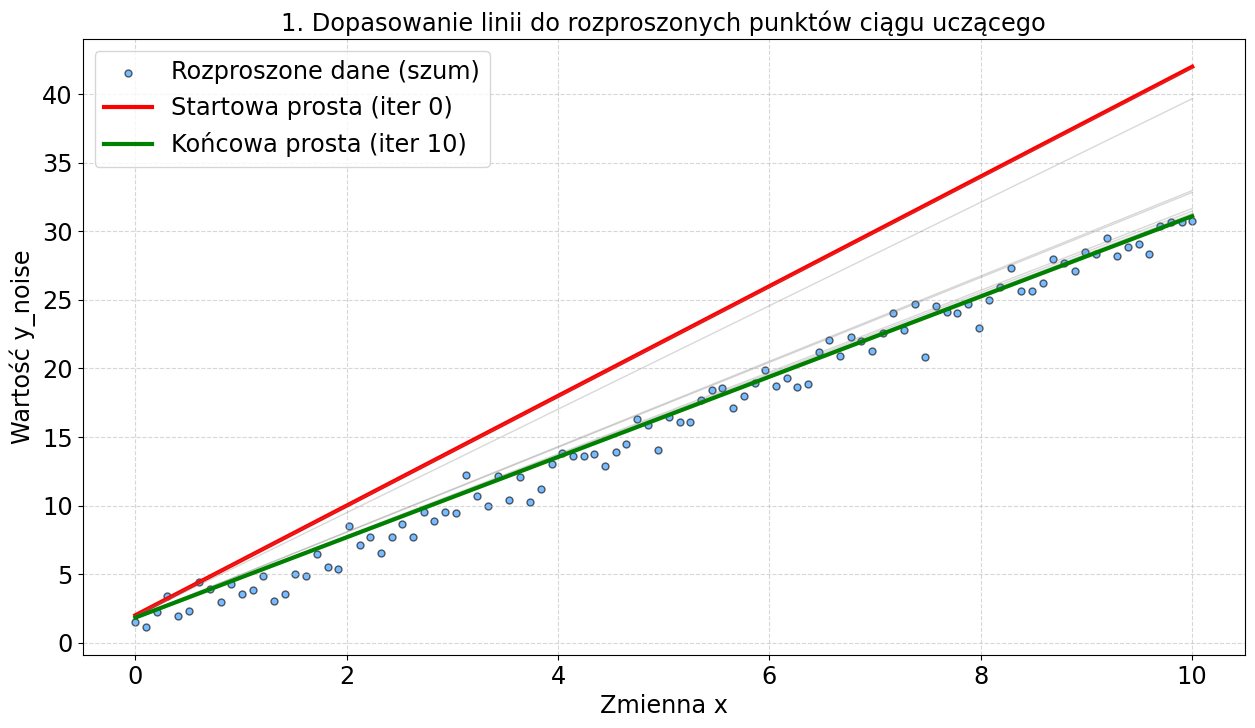

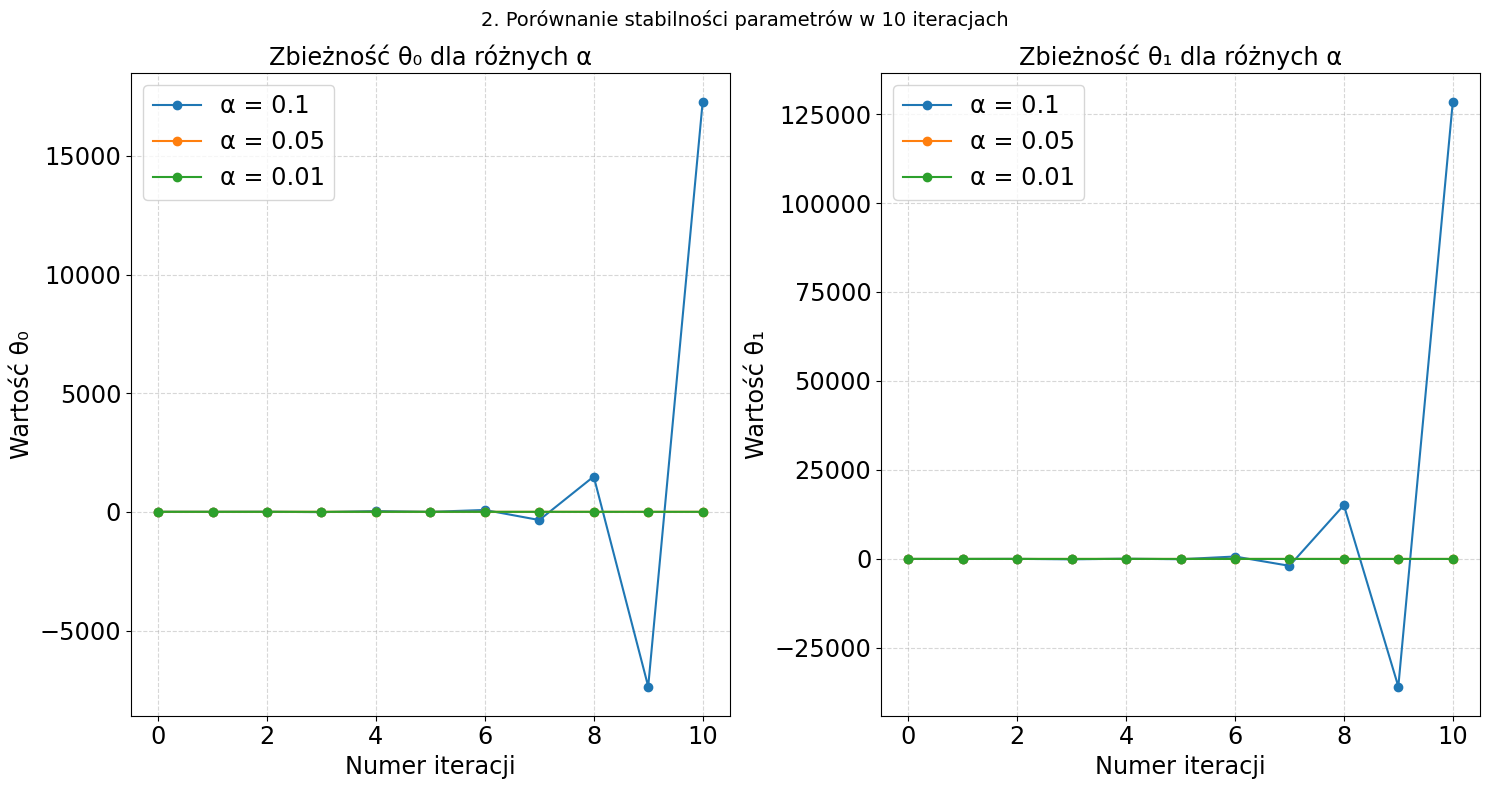

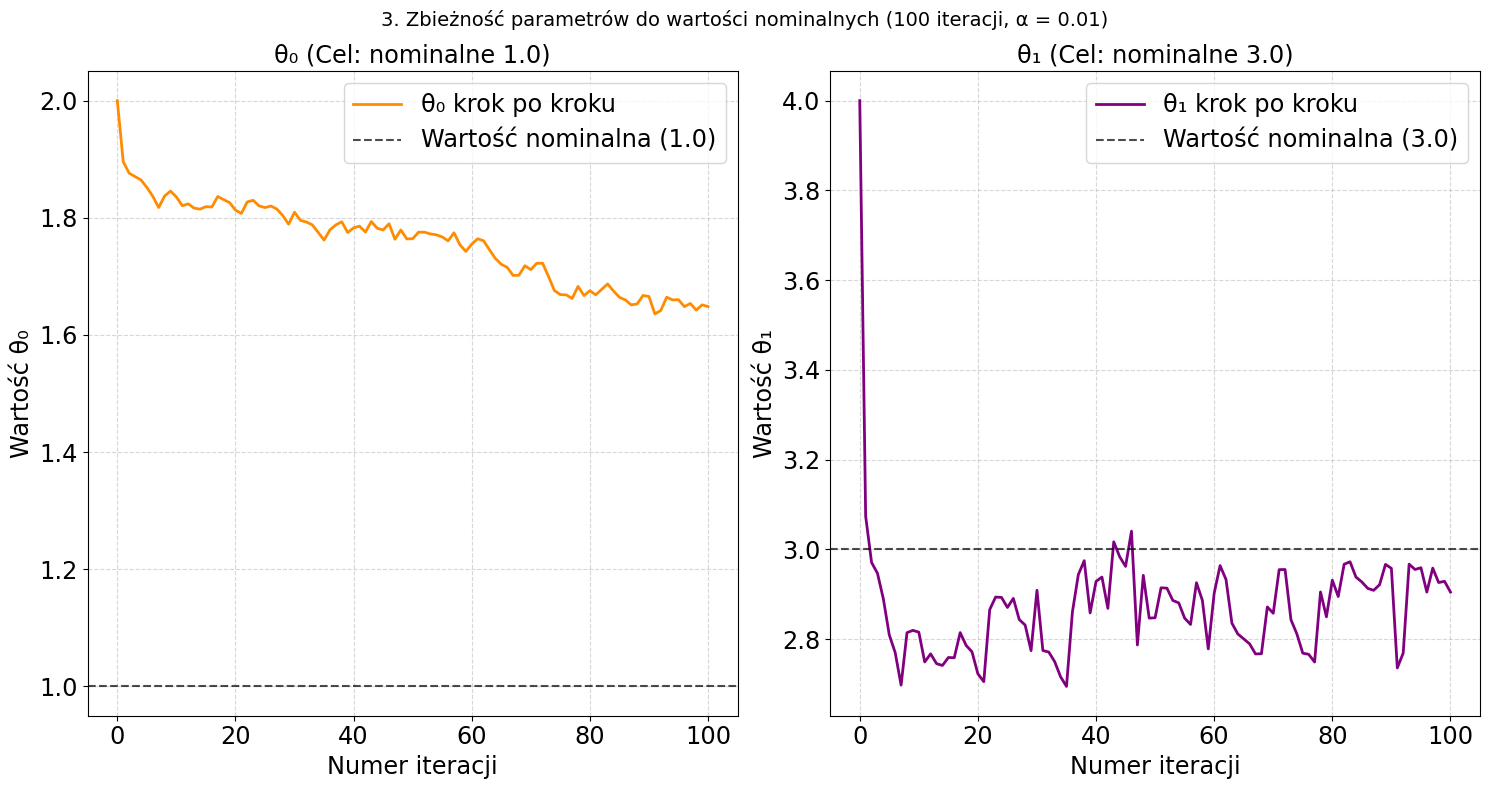

In [41]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import matplotlib.pyplot as plt

# Upewniamy się, że mamy świeże dane wejściowe do wykresów
x_data = df["x"].values
y_data = df["y_noise"].values
init_theta_test = theta + 1  # Punkt startowy [2.0, 4.0]

# Set-up globalny dla ładniejszego wyglądu wykresów
plt.rcParams['figure.figsize'] = (15, 8)

# ==============================================================================
# RYSUNEK 1: Rozproszone kropki i dopasowujące się linie (10 iteracji)
# ==============================================================================
alpha = 0.01
Iteration_no = 10
hist_10 = iterative_stochastic_gradient(x_data, y_data, init_theta_test, alpha, Iteration_no)

plt.figure()
# 1. Rysujemy rozproszone kropki za pomocą plt.scatter
plt.scatter(df["x"], df["y_noise"], color="dodgerblue", alpha=0.6, edgecolors='black', s=25, label='Rozproszone dane (szum)')

# 2. Generujemy proste regresji
x_line = np.linspace(0, 10, 2)
for i in range(len(hist_10)):
    t0, t1 = hist_10[i]
    y_line = t0 + t1 * x_line

    if i == 0:
        plt.plot(x_line, y_line, color="red", linewidth=3, label="Startowa prosta (iter 0)")
    elif i == 10:
        plt.plot(x_line, y_line, color="green", linewidth=3, label="Końcowa prosta (iter 10)")
    else:
        # Pozostałe linie rysujemy jako cienkie, szare linie (bez dodawania do legendy za każdym razem)
        plt.plot(x_line, y_line, color="gray", alpha=0.3, linewidth=1)

plt.title("1. Dopasowanie linii do rozproszonych punktów ciągu uczącego")
plt.xlabel("Zmienna x")
plt.ylabel("Wartość y_noise")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()


# ==============================================================================
# RYSUNEK 2: Wpływ różnych wartości α (10 iteracji)
# ==============================================================================
alphas = [0.1, 0.05, 0.01]
iterations_10 = np.arange(11)

# Tworzymy siatkę: 1 wiersz, 2 kolumny
fig, (ax1, ax2) = plt.subplots(1, 2)

for a in alphas:
    hist = iterative_stochastic_gradient(x_data, y_data, init_theta_test, a, 10)

    # Wykres dla theta_0 (lewe okienko)
    ax1.plot(iterations_10, hist[:, 0], marker='o', label=f'α = {a}')
    # Wykres dla theta_1 (prawe okienko)
    ax2.plot(iterations_10, hist[:, 1], marker='o', label=f'α = {a}')

# Dekoracja lewego wykresu (theta_0)
ax1.set_title("Zbieżność θ₀ dla różnych α")
ax1.set_xlabel("Numer iteracji")
ax1.set_ylabel("Wartość θ₀")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Dekoracja prawego wykresu (theta_1)
ax2.set_title("Zbieżność θ₁ dla różnych α")
ax2.set_xlabel("Numer iteracji")
ax2.set_ylabel("Wartość θ₁")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.suptitle("2. Porównanie stabilności parametrów w 10 iteracjach", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


# ==============================================================================
# RYSUNEK 3: Długofalowa zbieżność (100 iteracji, α = 0.01)
# ==============================================================================
hist_100 = iterative_stochastic_gradient(x_data, y_data, init_theta_test, 0.01, 100)
iterations_100 = np.arange(101)

fig, (ax1, ax2) = plt.subplots(1, 2)

# Wykres ścieżki theta_0 i czarna przerywana linia pozioma jako wartość docelowa (Cel = 1.0)
ax1.plot(iterations_100, hist_100[:, 0], color='darkorange', linewidth=2, label='θ₀ krok po kroku')
ax1.axhline(y=1.0, color='black', linestyle='--', alpha=0.7, label='Wartość nominalna (1.0)')
ax1.set_title("θ₀ (Cel: nominalne 1.0)")
ax1.set_xlabel("Numer iteracji")
ax1.set_ylabel("Wartość θ₀")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Wykres ścieżki theta_1 i wartość docelowa (Cel = 3.0)
ax2.plot(iterations_100, hist_100[:, 1], color='purple', linewidth=2, label='θ₁ krok po kroku')
ax2.axhline(y=3.0, color='black', linestyle='--', alpha=0.7, label='Wartość nominalna (3.0)')
ax2.set_title("θ₁ (Cel: nominalne 3.0)")
ax2.set_xlabel("Numer iteracji")
ax2.set_ylabel("Wartość θ₁")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.suptitle("3. Zbieżność parametrów do wartości nominalnych (100 iteracji, α = 0.01)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

## Algorytm gradientowy zbiorczy

**Proszę** napisać funkcję ```iterative_batch_gradient(x,y, theta, alpha, nIter)``` która:
* na wejściu przyjmuje ciąg uczący w postaci wektorów ```x``` i ```y```, wartości początkowe $(\theta_{0}, \theta_{1})$,
  parametr szybkości zbiegania $\alpha$ oraz liczbę iteracji ```nIter```
* implementuje wzór na parametry optymalne na podstawie [algorytmu najmniejszych kwadratów](https://brain.fuw.edu.pl/edu/index.php/Uczenie_maszynowe_i_sztuczne_sieci_neuronowe/Wyk%C5%82ad_1#Algorytm_najmniejszych_kwadrat.C3.B3w).
* zwraca estymowane parametry $(\theta_{0}^{est}, \theta_{1}^{est})$ dla wszystkich iteracji, czyli tablicę o kształcie
 $(nIter+1, 2)$. Początkową wartość $(\theta_{0}^{est}, \theta_{1}^{est})$ także należy dołączyc, stąd nIter+1 elementów
* funkcja powinna być przetestowana na czystych danych, czyli parze $(x,y)$ z poczatkową wartością $(\theta_{0}, \theta_{1})$ **równą** nominalnej
* funkcja powinna być przetestowana na czystych danych, czyli parze $(x,y)$ z poczatkową wartością $(\theta_{0}, \theta_{1})$ **różną** od nominalnej

In [44]:
%%time

def iterative_batch_gradient(x, y, init_theta, alpha, nIter):
    theta = init_theta
    theta_est = np.copy(theta)
    theta_est = np.reshape(theta_est, (-1,2))
    batchSize = len(x)
    for iteration in range(nIter):
         # --- Początek poprawionego kodu ---
        t0 = float(np.ravel(theta)[0])
        t1 = float(np.ravel(theta)[1])

        predictions = t0 + x * t1
        errors = predictions - y

        grad0 = np.mean(errors)
        grad1 = np.mean(errors * x)

        theta = np.array([[t0 - alpha * grad0, t1 - alpha * grad1]])
        # --- Koniec poprawionego kodu ---

        theta_est = np.append(theta_est, theta, axis=0)
    return theta_est

theta_est = iterative_batch_gradient(df["x"], df["y"], init_theta=theta, alpha=0.01, nIter=1)
print("Wartości estymowane z użyciem nominalnej wartości początkowej parametrów theta:",theta_est[-1])

theta_est = iterative_batch_gradient(df["x"], df["y"], init_theta=theta+1, alpha=0.01, nIter=500)
print("Wartości estymowane z użyciem różnej od nominalnej wartości początkowej parametrów theta:",theta_est[-1])

Wartości estymowane z użyciem nominalnej wartości początkowej parametrów theta: [1. 3.]
Wartości estymowane z użyciem różnej od nominalnej wartości początkowej parametrów theta: [1.23982705 2.96393956]
CPU times: user 169 ms, sys: 1.02 ms, total: 170 ms
Wall time: 177 ms


**Proszę** narysować następujące rysunki:
* dane oraz krzywe regressji dla 10 iteracji na jednym rysunku
* wartości parametrów $\theta_{0}$ i $\theta_{1}$ w funkcji numeru iteracji dla $\alpha$ = 0.1, 0.05 oraz 0.01 oraz 10 iteracji
* wartości parametrów $\theta_{0}$ i $\theta_{1}$ w funkcji numeru iteracji dla $\alpha$ = 0.01 dla 100 iteracji

W każdym przypadku jako wartości początkowe proszę przyjąć ($\theta_{0}$, $\theta_{1}$) + 1

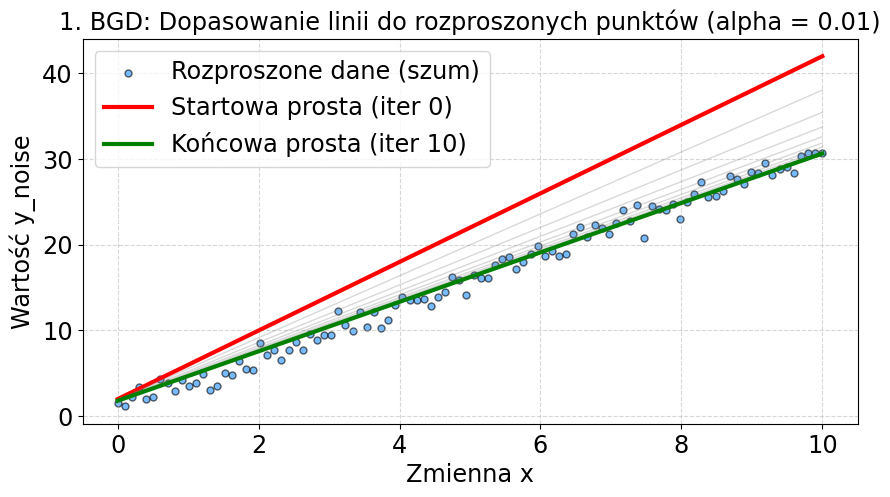

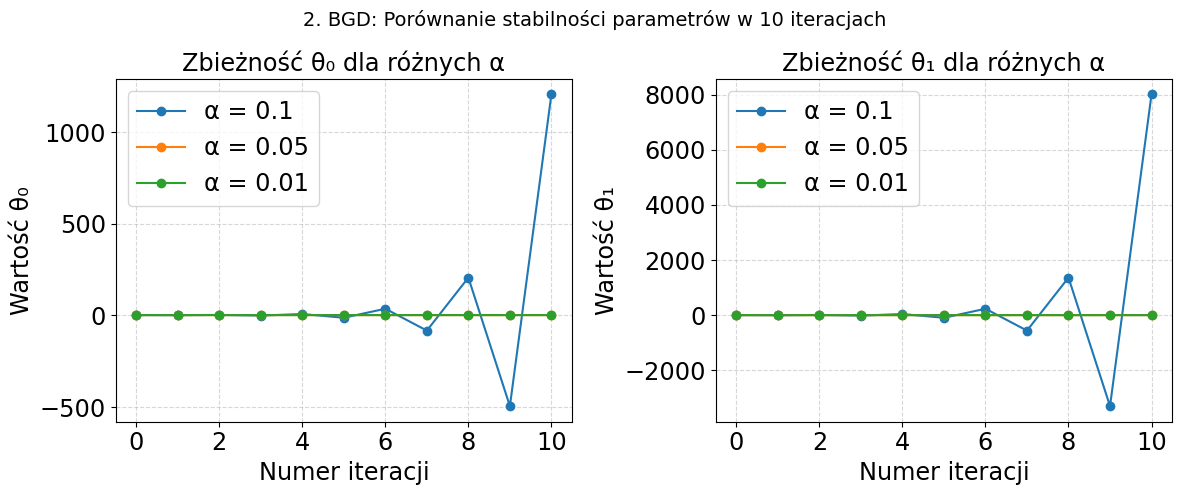

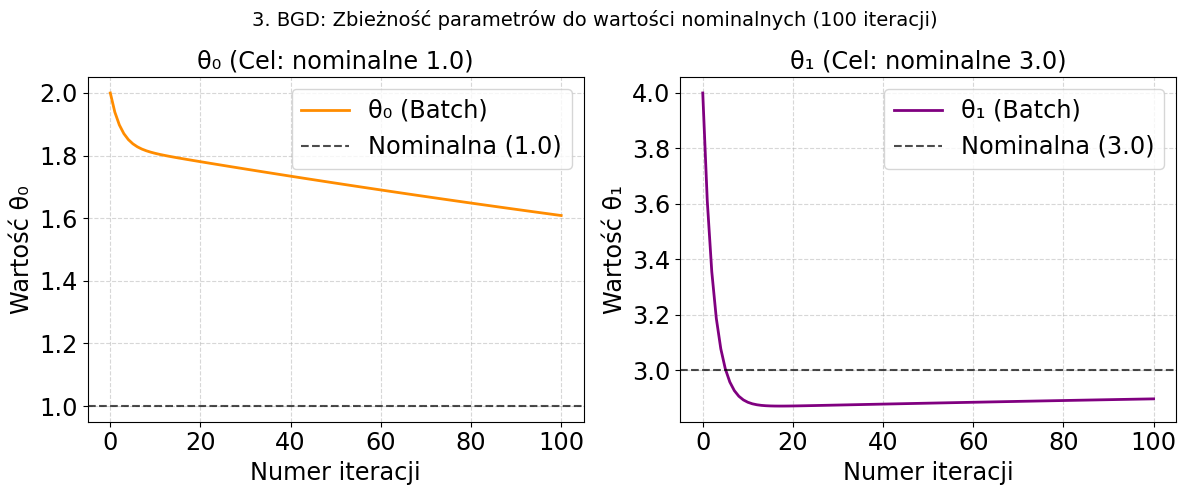

Finalna wartość parametrów dla alpha=0.1, nIter = 10:	 [1205.46933217 8009.42400657]
Finalna wartość parametrów dla alpha=0.05, nIter = 10:	 [1.71722686 2.9192604 ]
Finalna wartość parametrów dla alpha=0.01, nIter = 10:	 [1.80705227 2.88400501]
Finalna wartość parametrów dla alpha=0.01, nIter = 100:	 [1.60861431 2.89629774]
Oryginalna wartość parametrów:			 [1 3]


In [45]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import matplotlib.pyplot as plt


# Przygotowanie danych wejściowych (używamy zaszumionych y_noise dla efektu rozproszonych kropek)
x_data = df["x"].values
y_data = df["y_noise"].values
init_theta_test = theta + 1  # Punkt startowy [2.0, 4.0]

# --- OBLIÇZENIA DO WYPISANIA WYNIKÓW (wymagane przez printy prowadzącego) ---
theta_alpha_01 = iterative_batch_gradient(x_data, y_data, init_theta_test, alpha=0.1, nIter=10)
theta_alpha_005 = iterative_batch_gradient(x_data, y_data, init_theta_test, alpha=0.05, nIter=10)
theta_alpha_001 = iterative_batch_gradient(x_data, y_data, init_theta_test, alpha=0.01, nIter=10)
theta_alpha = iterative_batch_gradient(x_data, y_data, init_theta_test, alpha=0.01, nIter=100)


# ==============================================================================
# RYSUNEK 1: Dane oraz krzywe regresji zbiorczej dla 10 iteracji
# ==============================================================================
plt.figure(figsize=(10, 5))
# Rysujemy rozproszone punkty danych
plt.scatter(df["x"], df["y_noise"], color="dodgerblue", alpha=0.6, edgecolors='black', s=25, label='Rozproszone dane (szum)')

# Rysujemy proste regresji dla 10 iteracji (przy alpha = 0.01)
x_line = np.linspace(0, 10, 2)
for i in range(len(theta_alpha_001)):
    t0, t1 = theta_alpha_001[i].flatten()
    y_line = t0 + t1 * x_line

    if i == 0:
        plt.plot(x_line, y_line, color="red", linewidth=3, label="Startowa prosta (iter 0)")
    elif i == 10:
        plt.plot(x_line, y_line, color="green", linewidth=3, label="Końcowa prosta (iter 10)")
    else:
        plt.plot(x_line, y_line, color="gray", alpha=0.3, linewidth=1)

plt.title("1. BGD: Dopasowanie linii do rozproszonych punktów (alpha = 0.01)")
plt.xlabel("Zmienna x")
plt.ylabel("Wartość y_noise")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()


# ==============================================================================
# RYSUNEK 2: Wartości parametrów dla różnych alpha (10 iteracji)
# ==============================================================================
iterations_10 = np.arange(11)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Wykresy dla alpha = 0.1
ax1.plot(iterations_10, theta_alpha_01[:, 0], marker='o', label='α = 0.1')
ax2.plot(iterations_10, theta_alpha_01[:, 1], marker='o', label='α = 0.1')

# Wykresy dla alpha = 0.05
ax1.plot(iterations_10, theta_alpha_005[:, 0], marker='o', label='α = 0.05')
ax2.plot(iterations_10, theta_alpha_005[:, 1], marker='o', label='α = 0.05')

# Wykresy dla alpha = 0.01
ax1.plot(iterations_10, theta_alpha_001[:, 0], marker='o', label='α = 0.01')
ax2.plot(iterations_10, theta_alpha_001[:, 1], marker='o', label='α = 0.01')

ax1.set_title("Zbieżność θ₀ dla różnych α")
ax1.set_xlabel("Numer iteracji")
ax1.set_ylabel("Wartość θ₀")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

ax2.set_title("Zbieżność θ₁ dla różnych α")
ax2.set_xlabel("Numer iteracji")
ax2.set_ylabel("Wartość θ₁")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.suptitle("2. BGD: Porównanie stabilności parametrów w 10 iteracjach", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


# ==============================================================================
# RYSUNEK 3: Wartości parametrów dla alpha = 0.01 (100 iteracji)
# ==============================================================================
iterations_100 = np.arange(101)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Ścieżka theta_0 i linia docelowa (Cel = 1.0)
ax1.plot(iterations_100, theta_alpha[:, 0], color='darkorange', linewidth=2, label='θ₀ (Batch)')
ax1.axhline(y=1.0, color='black', linestyle='--', alpha=0.7, label='Nominalna (1.0)')
ax1.set_title("θ₀ (Cel: nominalne 1.0)")
ax1.set_xlabel("Numer iteracji")
ax1.set_ylabel("Wartość θ₀")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Ścieżka theta_1 i linia docelowa (Cel = 3.0)
ax2.plot(iterations_100, theta_alpha[:, 1], color='purple', linewidth=2, label='θ₁ (Batch)')
ax2.axhline(y=3.0, color='black', linestyle='--', alpha=0.7, label='Nominalna (3.0)')
ax2.set_title("θ₁ (Cel: nominalne 3.0)")
ax2.set_xlabel("Numer iteracji")
ax2.set_ylabel("Wartość θ₁")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.suptitle("3. BGD: Zbieżność parametrów do wartości nominalnych (100 iteracji)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

# --- wypisywanie wyników ---
print("Finalna wartość parametrów dla alpha=0.1, nIter = 10:\t", theta_alpha_01[-1])
print("Finalna wartość parametrów dla alpha=0.05, nIter = 10:\t", theta_alpha_005[-1])
print("Finalna wartość parametrów dla alpha=0.01, nIter = 10:\t", theta_alpha_001[-1])
print("Finalna wartość parametrów dla alpha=0.01, nIter = 100:\t", theta_alpha[-1])
print("Oryginalna wartość parametrów:\t\t\t", theta)


# Zadanie domowe

**Proszę:**


1. **Stwórz dane syntetyczne:**  
   - `X` w zakresie od 0 do 10, np. `X = np.linspace(0, 10, 100)`  
   - `y = 3 + 6 * X`, gdzie `theta_true = [3, 6]`  

2. **Ustaw parametry regresji liniowej:**  
   - Początkowe `theta_init = theta_true + 1`  
   - Współczynnik uczenia `alpha = 0.01`  
   - Liczba iteracji `nIter = 1000`  
   - Liczba poziomów szumu `nNoise = 50`  

3. **Stopniowe zaszumianie danych:**  
   - W pętli dla `i` od 0 do `nNoise-1` utwórz:
   
     ```python
     y_noise = y + i * np.random.randn(len(X))
     ```
   - Dla każdego `y_noise` dopasuj regresję liniową metodą batch gradient descent (`iterative_batch_gradient`)  
   - Zapisz finalne wartości theta w każdej iteracji

4. **Wizualizacja wyników:**  
   - Narysuj dopasowane proste dla wszystkich poziomów szumu  
   - **Uwaga:** Wybierz jeden kolor linii i uzależnij intensywność koloru od poziomu zaszumienia sygnału. Moża to zrobić na dużo sposobów.
   - Narysuj osobny wykres zmian `theta_0` i `theta_1` w funkcji poziomu szumu

---

## Dodatkowe pytanie

- Spróbuj zmienić zakres `X`, np. na:
  ```python
  X = np.linspace(0, 100, 1000)
  ```
  Zastanów się: co trzeba zmienić w kodzie, aby gradient descent nadal działał stabilnie?

In [ ]:
import numpy as np
import plotly.graph_objects as go
import matplotlib.cm as cm  # do generowania kolorów z colormap
import matplotlib.colors as mcolors

...


/tmp/ipykernel_22084/4051391825.py:17: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

